# Trạm mưa theo bốn hướng quanh Dã Viên — horizon 12 và 24 giờ

Mục tiêu: tìm trạm có tương quan dương cao nhất ở **Đông/Tây/Nam/Bắc**, đối chiếu hai trạm Model B (`750062`, `750007`). Không train model hoặc thay cấu hình production.

**Định nghĩa:** tại mốc t, tính Pearson/Spearman giữa tổng số đo mưa trong `(t−w, t]` và `ΔH_h(t) = H(t+h) − H(t)`, với h = 12/24 giờ, w = 1/3/6/12/24 giờ. Không dùng mưa tương lai. Tổng số đo giữ quy ước pipeline B; khoảng tích lũy vật lý của bản ghi nguồn chưa được xác minh, nên không diễn giải là cường độ mm/h.

Xếp hạng chính dùng **cửa sổ mưa 6 giờ cố định** (như phân tích trước), điểm bằng trung bình Pearson ở +12/+24h. Không tối ưu cửa sổ riêng từng trạm để tránh lợi thế do thử nhiều tổ hợp. Heatmap cho biết độ nhạy với cửa sổ khác.

Xếp hạng toàn giai đoạn là **khám phá**, không phải bằng chứng cải thiện dự báo. Bảng train riêng giúp phân biệt lựa chọn nguồn với kiểm tra độ ổn định. Các mẫu giờ chồng lấn và tự tương quan; không coi số mẫu là số quan sát độc lập, không suy luận nhân quả hay lưu vực từ hướng địa lý.


In [1]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/ai").is_dir())
SNAPSHOT = ROOT / "reports/rain_regions_h12_h24_20261019"
DATASET = ROOT / "train_data/da_vien_1h_2026-10-15"
WINDOWS = [1, 3, 6, 12, 24]
HORIZONS = [12, 24]
PRIMARY_WINDOW = 6
MIN_COVERAGE = 0.90
MIN_PAIRS = 200
MIN_COMMON_COVERAGE = 0.50
MODEL_B = {"750062", "750007"}
DIRECTIONS = ["Bắc", "Đông", "Nam", "Tây"]
COLORS = dict(zip(DIRECTIONS, ["#2878b5", "#e58c27", "#39956a", "#9564a8"]))
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

def show():
    buffer = BytesIO()
    plt.gcf().savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close()

def normalize_id(values):
    return values.astype(str).str.lstrip("0")

## 1. Nguồn dữ liệu và kiểm tra độ phủ
Ưu tiên snapshot PostgreSQL chỉ đọc đã xuất ngày 19/10, gồm 55 trạm đến 15/10. Nếu không còn snapshot, dùng CSV gốc trong `data/` và **in rõ giai đoạn ngắn hơn**. Không truy cập mạng/DB, không xuất file phụ. Giờ thiếu giữ NaN; giờ có một phần số đo vẫn có thể tạo tổng không đầy đủ, nên bảng số bản ghi/giờ được hiển thị để kiểm tra.


In [2]:
water_meta = pd.read_csv(ROOT / "data/water_level_stations.csv.gz", dtype={"code": str})
da_vien = water_meta.loc[normalize_id(water_meta.code).eq("74647403")].iloc[0]
LON0, LAT0 = json.loads(da_vien.geom)["coordinates"][:2]
required = [SNAPSHOT / name for name in ["station_catalog.csv", "hourly_rain.csv.gz", "export.json"]]
if all(p.exists() for p in required):
    catalog = pd.read_csv(required[0], dtype={"id": str}).rename(columns={"id": "station_id"})
    raw = pd.read_csv(required[1], dtype={"station_id": str})
    raw["timestamp_utc"] = pd.to_datetime(raw.timestamp_utc, utc=True)
    raw["station_id"] = normalize_id(raw.station_id)
    assert not raw.duplicated(["station_id", "timestamp_utc"]).any()
    raw.loc[raw.n_invalid.gt(0), "rain_mm"] = np.nan
    rain = raw.pivot(index="timestamp_utc", columns="station_id", values="rain_mm")
    sampling = raw.groupby("station_id").agg(hours=("n_valid", "size"), median_valid_per_hour=("n_valid", "median"), invalid_records=("n_invalid", "sum"))
    hourly = pd.read_csv(DATASET / "hourly.csv", usecols=["timestamp_utc", "water_level_depth"])
    hourly["timestamp_utc"] = pd.to_datetime(hourly.timestamp_utc, utc=True)
    water = hourly.set_index("timestamp_utc").water_level_depth
    source = "Snapshot PostgreSQL 19/10/2026 + hourly dataset Model B"
    display(json.loads(required[2].read_text()))
else:
    catalog = pd.read_csv(ROOT / "data/rain_stations.csv.gz", dtype={"code": str}).rename(columns={"code": "station_id"})
    coords = catalog.geom.map(lambda value: json.loads(value)["coordinates"])
    catalog["longitude"] = coords.map(lambda value: value[0])
    catalog["latitude"] = coords.map(lambda value: value[1])
    raw = pd.read_csv(ROOT / "data/rain_observations.csv.gz", dtype={"station_id": str})
    raw["station_id"] = normalize_id(raw.station_id)
    raw["time"] = pd.to_datetime(raw.time_point, utc=True)
    raw["depth"] = pd.to_numeric(raw.depth, errors="coerce")
    raw.loc[raw.depth.lt(0), "depth"] = np.nan
    groups = raw.groupby([pd.Grouper(key="time", freq="1h", closed="right", label="right"), "station_id"])
    rain = groups.depth.sum(min_count=1).unstack("station_id")
    sampling = groups.depth.count().groupby("station_id").agg(["size", "median"]).rename(columns={"size": "hours", "median": "median_valid_per_hour"})
    observations = pd.read_csv(ROOT / "data/water_level_observations.csv.gz", dtype={"station_id": str})
    observations = observations.loc[normalize_id(observations.station_id).eq("74647403")].copy()
    observations["time"] = pd.to_datetime(observations.time_point, utc=True)
    water = observations.set_index("time").depth.resample("1h", closed="right", label="right").mean()
    source = "CSV gốc data/ — giai đoạn có thể ngắn hơn dataset Model B"

catalog["station_id"] = normalize_id(catalog.station_id)
assert catalog.station_id.is_unique
index = pd.date_range(water.index.min(), water.index.max(), freq="1h")
water = water.reindex(index).astype(float)
rain = rain.reindex(index).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
rain = rain.mask(rain.lt(0))
delta = {h: water.shift(-h) - water for h in HORIZONS}
print(source)
print(f"Dã Viên: {LAT0:.6f}, {LON0:.6f}")
print(f"Giai đoạn UTC+7: {index.min().tz_convert('Asia/Ho_Chi_Minh')} → {index.max().tz_convert('Asia/Ho_Chi_Minh')}")
print(f"{len(index):,} giờ; {rain.shape[1]} mã trạm mưa; nước hợp lệ {water.notna().mean():.1%}")
print("Mã trạm không có metadata:", sorted(set(rain.columns) - set(catalog.station_id)))
display(sampling.round(2))

Snapshot PostgreSQL 19/10/2026 + hourly dataset Model B
Dã Viên: 16.458944, 107.571361
Giai đoạn UTC+7: 2025-11-15 02:00:00+07:00 → 2026-10-15 14:00:00+07:00
8,029 giờ; 55 mã trạm mưa; nước hợp lệ 100.0%
Mã trạm không có metadata: []


{'n_stations': 55,
 'station_hours': 431690,
 'start_utc': '2025-11-14 19:00:00+00:00',
 'end_utc': '2026-10-15 07:00:00+00:00',
 'aggregation': 'source sums in (t-1h,t]; missing not zero',
 'caution': 'Same source-sum convention as B; physical raw accumulation intervals not independently reverified',
 'database_read_only': True}

,hours,median_valid_per_hour,invalid_records
station_id,,,
14690,8013,6.0,0
14696,8029,6.0,0
14699,8002,6.0,0
228005,4927,6.0,0
228006,6372,6.0,0
567011,8015,6.0,0
677493,8029,6.0,0
677851,8029,6.0,0
678628,8029,6.0,0


## 2. Phân hướng và bản đồ tọa độ
Góc phương vị cầu từ Dã Viên: Bắc `[315°,360°) ∪ [0°,45°)`, Đông `[45°,135°)`, Nam `[135°,225°)`, Tây `[225°,315°)`. Mỗi trạm chỉ thuộc một hướng; đây là bốn cung 90°, **khác** quy tắc vùng địa lý của báo cáo cũ. Trạm trùng tọa độ Dã Viên không được gán hướng.


In [3]:
lat = np.radians(catalog.latitude.to_numpy(float))
lon_delta = np.radians(catalog.longitude.to_numpy(float) - LON0)
lat0 = np.radians(LAT0)
y = np.sin(lon_delta) * np.cos(lat)
x = np.cos(lat0) * np.sin(lat) - np.sin(lat0) * np.cos(lat) * np.cos(lon_delta)
catalog["bearing_deg"] = (np.degrees(np.arctan2(y, x)) + 360) % 360
angle = np.sin((lat - lat0) / 2)**2 + np.cos(lat0) * np.cos(lat) * np.sin(lon_delta / 2)**2
catalog["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(angle, 0, 1)))
catalog["direction"] = catalog.bearing_deg.map(lambda b: DIRECTIONS[int((b + 45) // 90) % 4] if np.isfinite(b) else None)
catalog.loc[catalog.distance_km.lt(0.001), "direction"] = None
catalog["model_B"] = catalog.station_id.isin(MODEL_B)
catalog["coverage"] = catalog.station_id.map(rain.notna().mean())
catalog["label"] = catalog.station_id + " · " + catalog.name
catalog = catalog.set_index("station_id", drop=False)
display(catalog[["station_id", "name", "direction", "bearing_deg", "distance_km", "coverage", "model_B"]].sort_values(["direction", "distance_km"]).round(3))
print("Hai trạm Model B:")
display(catalog.loc[catalog.model_B, ["name", "direction", "bearing_deg", "distance_km"]].round(2))

Hai trạm Model B:


,station_id,name,direction,bearing_deg,distance_km,coverage,model_B
station_id,,,,,,,
567011,567011,Quan Tượng Đài (Phú Xuân),Bắc,351.251,0.367,0.998,False
750033,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,333.188,3.832,1.000,False
750032,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,3.634,11.260,1.000,False
750059,750059,Cảng Thuận An,Bắc,34.512,12.029,1.000,False
677851,677851,TT Sịa (Quảng Điền),Bắc,335.785,15.438,1.000,False
750045,750045,Đan Điền (Đập Cửa Lác),Bắc,324.342,25.771,1.000,False
750064,750064,Điền Hương (Phong Điền),Bắc,321.092,35.215,0.983,False
750024,750024,An Tây (Thuận Hóa),Nam,135.296,3.963,0.995,False
750063,750063,Phú Sơn (Hương Thủy),Nam,141.443,17.059,0.965,False


,name,direction,bearing_deg,distance_km
station_id,,,,
750007,Nhâm (A Lưới),Tây,237.75,49.48
750062,Hồng Thái (A Lưới),Tây,235.34,42.80


## 3. Correlation từng cửa sổ, từng horizon
Coverage correlation = số cặp hợp lệ / số anchor có ΔH hợp lệ và đủ lịch sử theo cửa sổ. Không điền 0 vào dữ liệu thiếu. Hạng chính yêu cầu ≥90% coverage và ≥200 cặp ở **cả hai horizon**; có thể đổi ngưỡng ở cell cấu hình. Tương quan với mức nước tuyệt đối được đưa thêm để đối chiếu, không dùng chọn nguồn.


In [4]:
accumulated = {w: rain.rolling(w, min_periods=w).sum() for w in WINDOWS}
manifest = json.loads((DATASET / "manifest.json").read_text())
split_masks = {"all": pd.Series(True, index=index)}
for split, spec in manifest["splits"].items():
    start, end = pd.Timestamp(spec["start_utc"]), pd.Timestamp(spec["end_utc"])
    split_masks[split] = pd.Series((index >= start) & (index <= end), index=index)

rows = []
for split, mask in split_masks.items():
    for w in WINDOWS:
        for h in HORIZONS:
            # Không để nhãn tương lai vượt biên split.
            future_in_split = mask.shift(-h, fill_value=False) if split != "all" else mask
            eligible = mask & future_in_split & delta[h].notna() & (np.arange(len(index)) >= w - 1)
            for sid in rain.columns:
                a = accumulated[w][sid]
                valid = eligible & a.notna()
                n = int(valid.sum())
                can_correlate = n >= 3 and a[valid].nunique() > 1 and delta[h][valid].nunique() > 1
                rows.append(dict(split=split, station_id=sid, window=w, horizon=h, n=n,
                    coverage=n / max(int(eligible.sum()), 1),
                    pearson=a[valid].corr(delta[h][valid]) if can_correlate else np.nan,
                    spearman=a[valid].corr(delta[h][valid], method="spearman") if can_correlate else np.nan,
                    level_r=a[valid].corr(water.shift(-h)[valid]) if can_correlate else np.nan))
results = pd.DataFrame(rows).merge(catalog[["name", "direction", "model_B"]], left_on="station_id", right_index=True, how="left")
primary = results.loc[results.window.eq(PRIMARY_WINDOW)].copy()
primary["qualified"] = primary.coverage.ge(MIN_COVERAGE) & primary.n.ge(MIN_PAIRS) & primary.pearson.notna()
ranking = primary.pivot(index=["split", "station_id", "name", "direction", "model_B"], columns="horizon", values=["pearson", "spearman", "n", "coverage", "qualified"])
ranking.columns = [f"{metric}_{h}" for metric, h in ranking.columns]
ranking = ranking.reset_index()
ranking["score"] = ranking[["pearson_12", "pearson_24"]].mean(axis=1, skipna=False)
ranking["eligible"] = ranking.qualified_12.eq(True) & ranking.qualified_24.eq(True)
ranking = ranking.sort_values(["split", "score"], ascending=[True, False])
print("Xếp hạng toàn giai đoạn (pairwise; chưa chuẩn hóa tập anchor giữa các trạm):")
display(ranking.loc[ranking.split.eq("all"), ["station_id", "name", "direction", "model_B", "pearson_12", "pearson_24", "spearman_12", "spearman_24", "n_12", "n_24", "coverage_12", "coverage_24", "score", "eligible"]].round(3))

Xếp hạng toàn giai đoạn (pairwise; chưa chuẩn hóa tập anchor giữa các trạm):


,station_id,name,direction,model_B,pearson_12,pearson_24,spearman_12,spearman_24,n_12,n_24,coverage_12,coverage_24,score,eligible
48,750062,Hồng Thái (A Lưới),Tây,True,0.297484,0.211006,0.013684,-0.066903,8006,7994,0.999251,0.99925,0.254245,True
16,750007,Nhâm (A Lưới),Tây,True,0.27718,0.163308,-0.000095,-0.087263,8012,8000,1.0,1.0,0.220244,True
13,750003,Thị trấn A Lưới (A Lưới),Tây,False,0.265856,0.161707,0.015148,-0.057109,7989,7977,0.997129,0.997125,0.213782,True
20,750011,Hồ A Lá (A Lưới),Tây,False,0.259911,0.154644,0.020504,-0.067746,8012,8000,1.0,1.0,0.207278,True
8,678628,Tà Lương (A Lưới),Tây,False,0.179722,0.051424,0.002314,-0.069812,8012,8000,1.0,1.0,0.115573,True
35,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),Đông,False,0.148958,0.059576,0.008193,-0.050459,8012,8000,1.0,1.0,0.104267,True
26,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đông,False,0.102488,0.087686,0.005418,-0.068661,8012,8000,1.0,1.0,0.095087,True
0,14690,Hồ chứa nước Thủy Yên,Đông,False,0.10402,0.041577,0.006037,-0.059612,7991,7979,0.997379,0.997375,0.072799,True
36,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,False,0.050113,0.078627,0.015007,-0.057701,8012,8000,1.0,1.0,0.06437,True
44,750046,Vỹ Dạ,Đông,False,0.032278,0.087122,-0.015593,-0.056604,8012,8000,1.0,1.0,0.0597,True


## 4. Chọn một trạm mỗi hướng trên cùng tập anchor
Để trạm ít dữ liệu không được lợi do chỉ quan sát các đợt thuận lợi, lấy **giao anchor của các ứng viên đủ coverage trong mỗi hướng**, rồi tính lại r12/r24 trên chính tập đó. Hai horizon cũng dùng chung anchor. Chỉ chọn khi giao còn ≥50% anchor mục tiêu, ≥200 mẫu và score dương. Nếu không đạt, hiển thị “chưa đủ dữ liệu”, không ép chọn. Các hướng có thể có tập anchor khác nhau: chỉ so xếp hạng **trong cùng hướng**.

Bảng `all` trả lời câu hỏi khám phá toàn dataset; bảng `train` là lựa chọn train-only riêng biệt. Không dùng kết quả all để tuyên bố validation/test độc lập.


In [5]:
common_rows = []
audit_rows = []
for split, mask in split_masks.items():
    pool = ranking.loc[ranking.split.eq(split) & ranking.eligible]
    for direction in DIRECTIONS:
        ids = pool.loc[pool.direction.eq(direction), "station_id"].tolist()
        base = mask & delta[12].notna() & delta[24].notna() & (np.arange(len(index)) >= PRIMARY_WINDOW - 1)
        if split != "all":
            base &= mask.shift(-24, fill_value=False)
        common = base & accumulated[PRIMARY_WINDOW][ids].notna().all(axis=1) if ids else base & False
        count = int(common.sum())
        fraction = count / max(int(base.sum()), 1)
        audit_rows.append(dict(split=split, direction=direction, candidates=len(ids), common_n=count, common_coverage=fraction))
        for sid in ids:
            a = accumulated[PRIMARY_WINDOW].loc[common, sid]
            r = {h: a.corr(delta[h][common]) if a.nunique() > 1 and delta[h][common].nunique() > 1 else np.nan for h in HORIZONS}
            common_rows.append(dict(split=split, direction=direction, station_id=sid, name=catalog.loc[sid, "name"], model_B=sid in MODEL_B,
                r12=r[12], r24=r[24], score=(r[12] + r[24]) / 2, n=count, coverage=fraction,
                qualified=count >= MIN_PAIRS and fraction >= MIN_COMMON_COVERAGE))
common_ranking = pd.DataFrame(common_rows)
assert not common_ranking.empty, "Không có ứng viên: xem coverage và ngưỡng cấu hình."
common_ranking = common_ranking.sort_values(["split", "direction", "score", "station_id"], ascending=[True, True, False, True])
winners = common_ranking.loc[common_ranking.qualified & common_ranking.score.gt(0)].groupby(["split", "direction"], sort=False).head(1)
display(pd.DataFrame(audit_rows).round(3))
for split in ["all", "train"]:
    print(f"Trạm được chọn — {split}; cửa sổ {PRIMARY_WINDOW}h; score = (r12 + r24) / 2")
    selected = winners.loc[winners.split.eq(split)]
    display(selected.round(3))
    print("Chưa chọn được:", sorted(set(DIRECTIONS) - set(selected.direction)))
print("Top 5 mỗi hướng trên toàn giai đoạn, cùng anchor:")
display(common_ranking.loc[common_ranking.split.eq("all")].groupby("direction", sort=False).head(5).round(3))

Trạm được chọn — all; cửa sổ 6h; score = (r12 + r24) / 2
Chưa chọn được: []
Trạm được chọn — train; cửa sổ 6h; score = (r12 + r24) / 2
Chưa chọn được: []
Top 5 mỗi hướng trên toàn giai đoạn, cùng anchor:


,split,direction,candidates,common_n,common_coverage
0,all,Bắc,7,7835,0.979
1,all,Đông,17,6832,0.854
2,all,Nam,12,6636,0.830
3,all,Tây,16,7286,0.911
4,train,Bắc,7,6062,0.984
5,train,Đông,17,5332,0.865
6,train,Nam,11,5454,0.885
7,train,Tây,16,5707,0.926
8,val,Bắc,7,1004,0.951
9,val,Đông,16,987,0.935


,split,direction,station_id,name,model_B,r12,r24,score,n,coverage,qualified
0,all,Bắc,750032,Trạm bơm Quảng Thành (Quảng Điền),False,0.051,0.079,0.065,7835,0.979,True
25,all,Nam,750042,Trạm kiểm lâm Khe Mỏ Rang,False,0.096,0.041,0.068,6636,0.830,True
36,all,Tây,750062,Hồng Thái (A Lưới),True,0.367,0.333,0.350,7286,0.911,True
7,all,Đông,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),False,0.156,0.068,0.112,6832,0.854,True


,split,direction,station_id,name,model_B,r12,r24,score,n,coverage,qualified
52,train,Bắc,750032,Trạm bơm Quảng Thành (Quảng Điền),False,0.091,0.177,0.134,6062,0.984,True
77,train,Nam,750061,Thủy điện Bình Điền (Hương Trà),False,0.287,0.207,0.247,5454,0.885,True
88,train,Tây,750062,Hồng Thái (A Lưới),True,0.491,0.487,0.489,5707,0.926,True
59,train,Đông,750027,Thủy Thanh (Hương Thủy),False,0.090,0.235,0.162,5332,0.865,True


,split,direction,station_id,name,model_B,r12,r24,score,n,coverage,qualified
0,all,Bắc,750032,Trạm bơm Quảng Thành (Quảng Điền),False,0.051,0.079,0.065,7835,0.979,True
1,all,Bắc,677851,TT Sịa (Quảng Điền),False,0.037,0.064,0.051,7835,0.979,True
2,all,Bắc,567011,Quan Tượng Đài (Phú Xuân),False,0.025,0.074,0.049,7835,0.979,True
3,all,Bắc,750033,VP QLKTCTTL TP Huế (TP Huế),False,0.027,0.063,0.045,7835,0.979,True
4,all,Bắc,750045,Đan Điền (Đập Cửa Lác),False,0.045,0.038,0.041,7835,0.979,True
25,all,Nam,750042,Trạm kiểm lâm Khe Mỏ Rang,False,0.096,0.041,0.068,6636,0.830,True
27,all,Nam,750012,"Đập, Thủy điện Thượng Nhật (Phú Lộc)",False,0.096,0.038,0.067,6636,0.830,True
26,all,Nam,750015,Hồ Tà Rinh (Phú Lộc),False,0.085,0.043,0.064,6636,0.830,True
29,all,Nam,677493,TT Khe Tre (Phú Lộc),False,0.060,0.002,0.031,6636,0.830,True
33,all,Nam,750029,Thượng Quảng (Phú Lộc),False,0.048,-0.005,0.021,6636,0.830,True


## 5. Bản đồ, xếp hạng và độ nhạy cửa sổ
Bản đồ tọa độ không cần tải nền Internet. Sao đỏ là Dã Viên; vòng đen đánh dấu Model B; nhãn `★` là trạm được chọn trên toàn giai đoạn. Bốn đường chéo là ranh giới cung hướng.


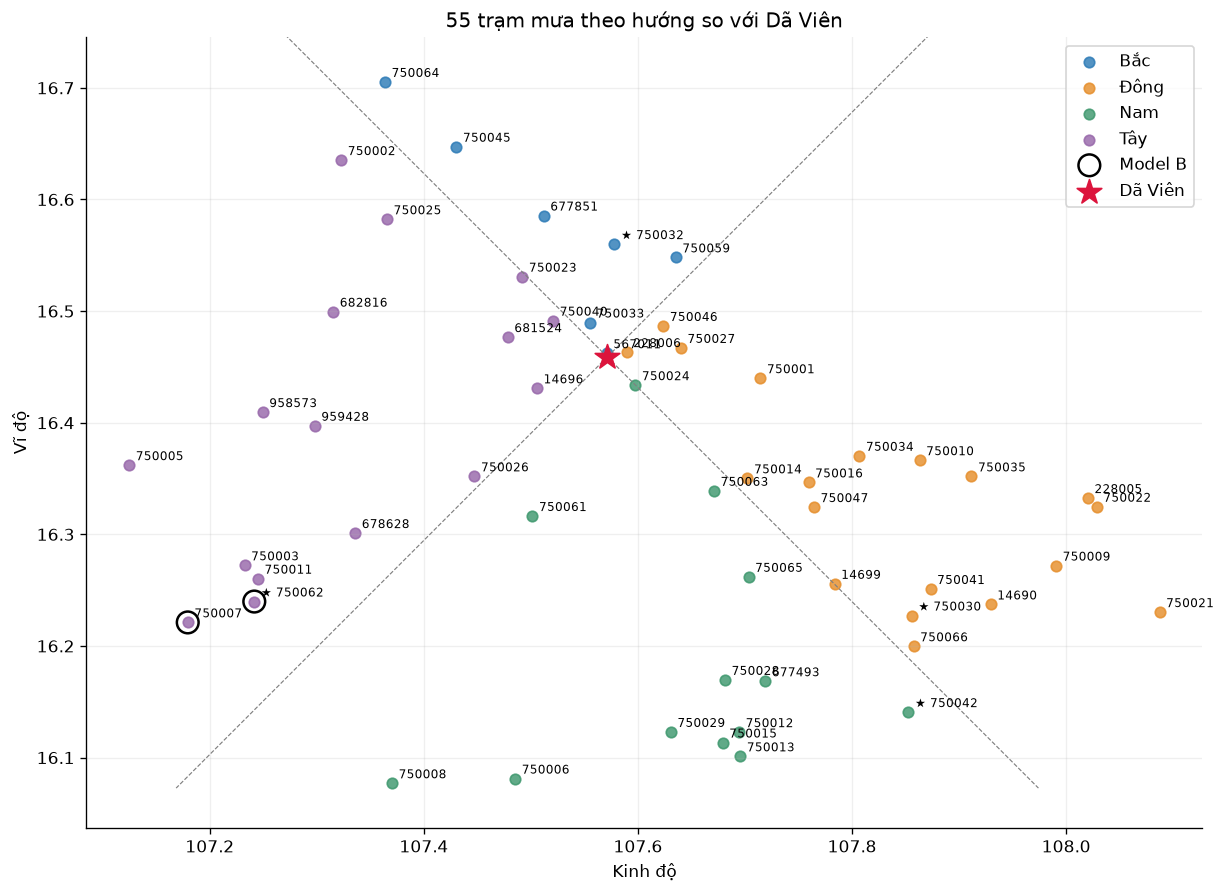

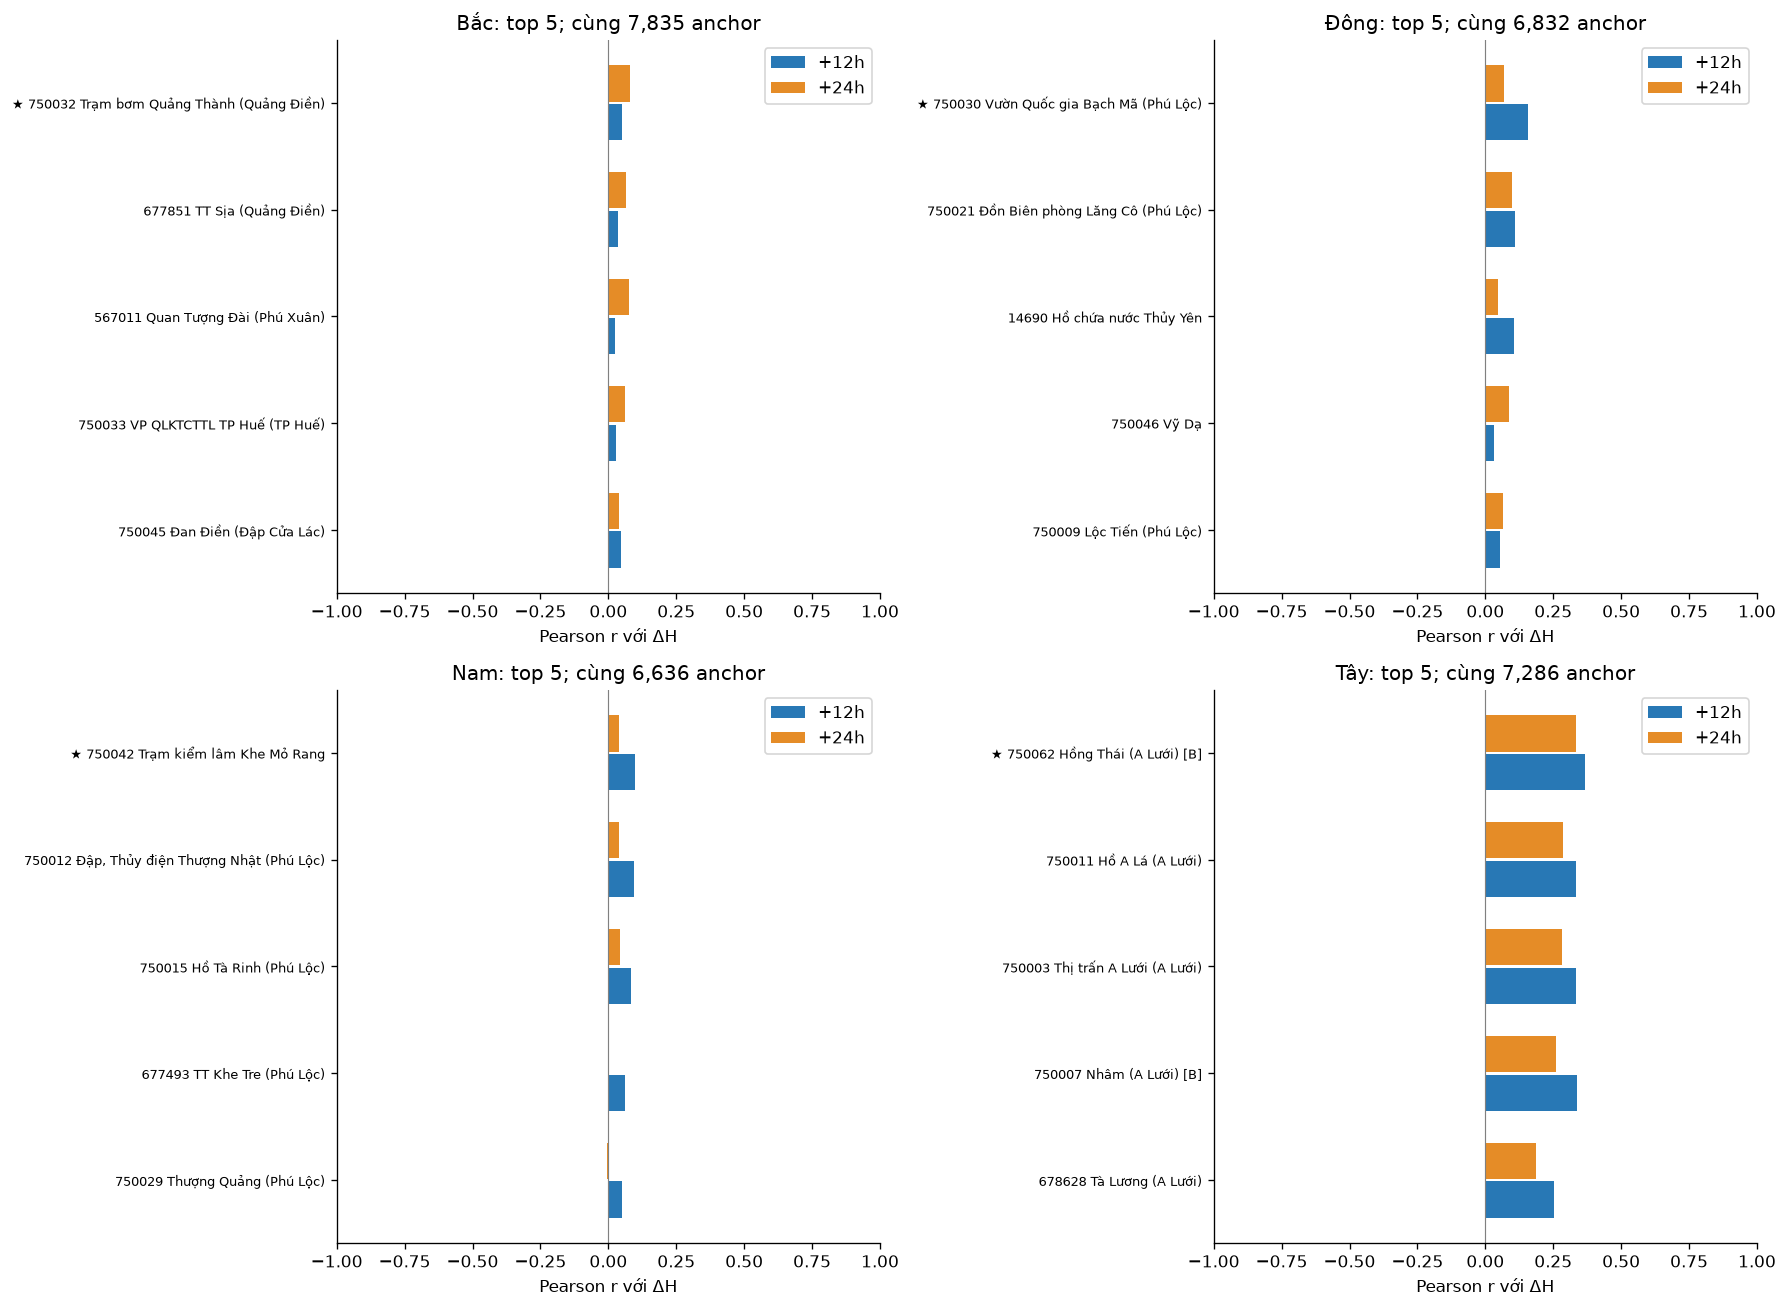

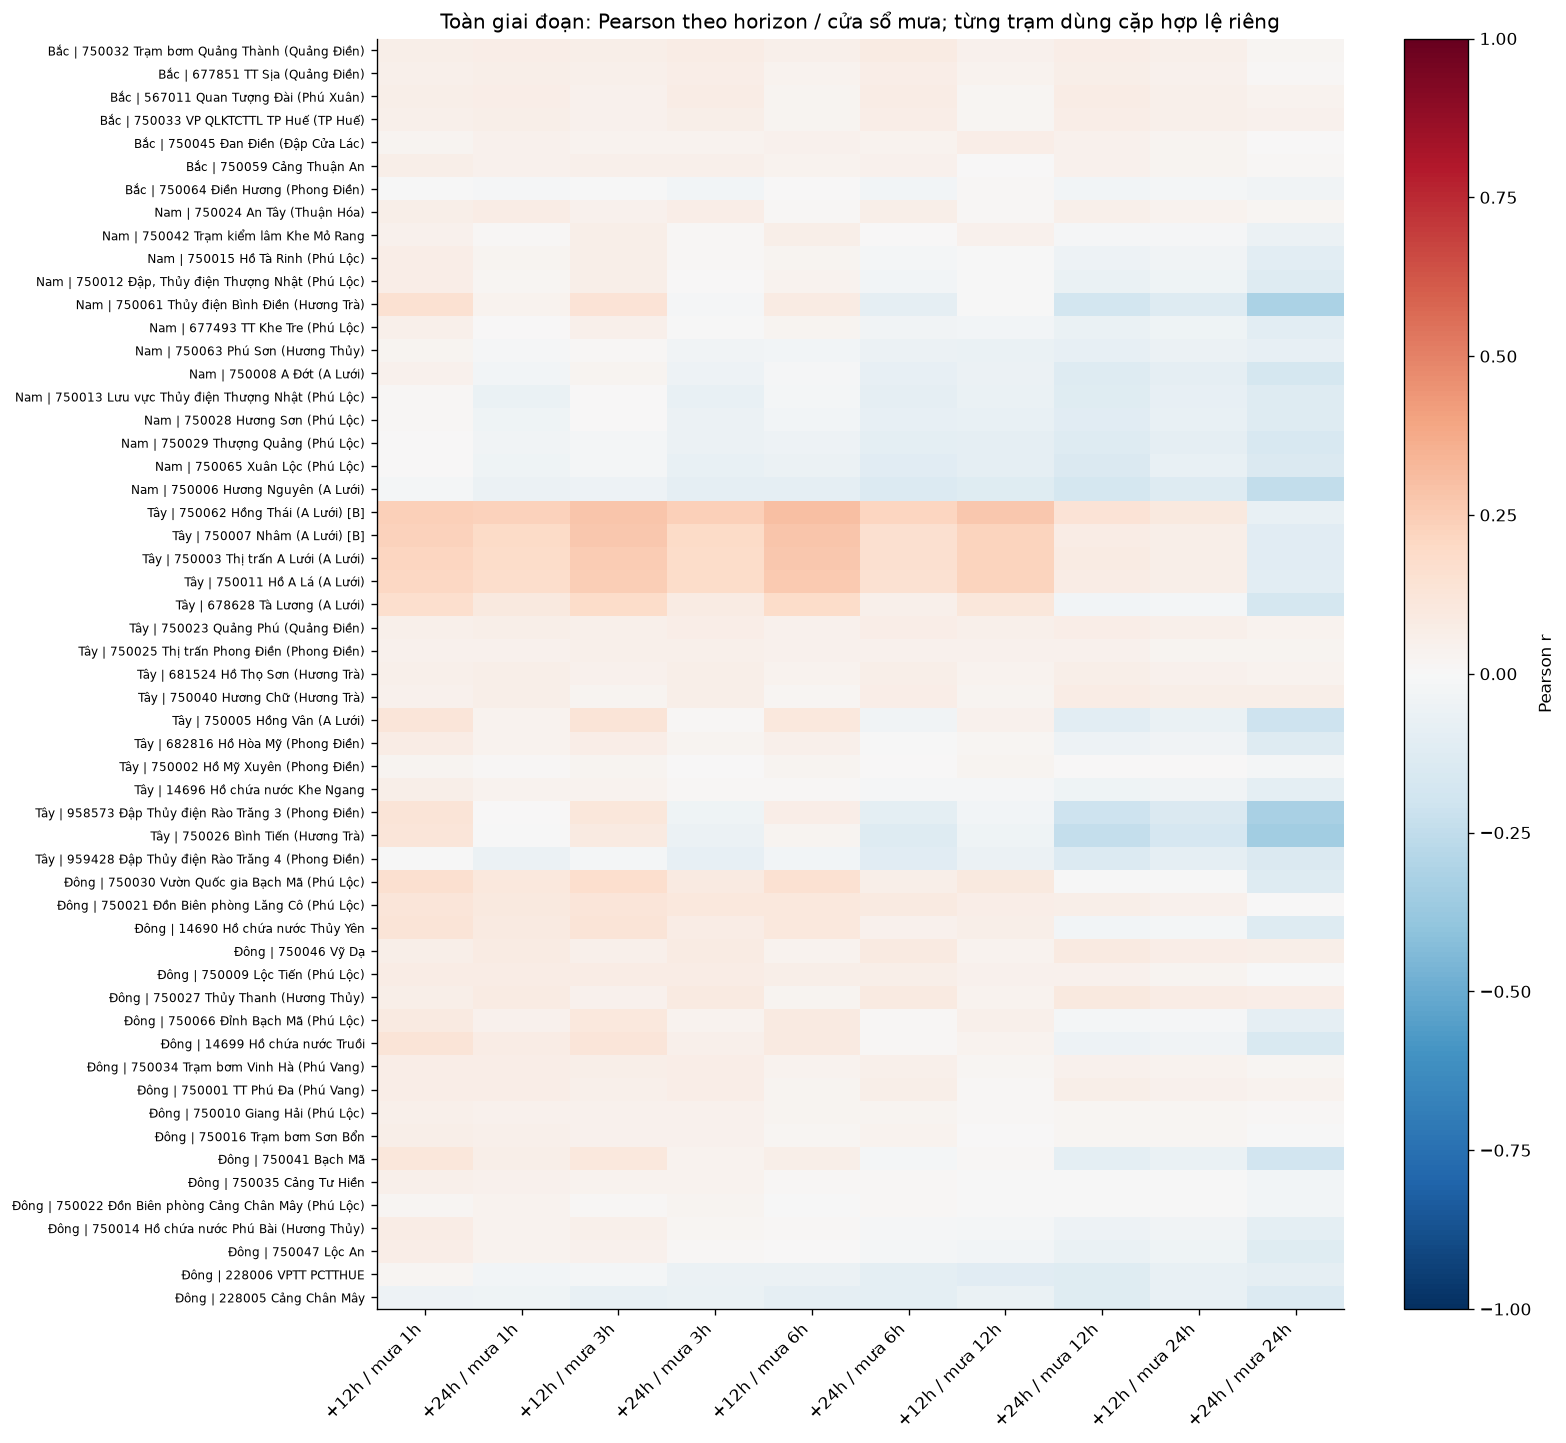

In [6]:
selected_all = winners.loc[winners.split.eq("all")]
chosen = set(selected_all.station_id)
fig, ax = plt.subplots(figsize=(12, 10))
for direction in DIRECTIONS:
    group = catalog.loc[catalog.direction.eq(direction)]
    ax.scatter(group.longitude, group.latitude, label=direction, color=COLORS[direction], s=40, alpha=0.8)
for sid, row in catalog.iterrows():
    ax.annotate(("★ " if sid in chosen else "") + sid, (row.longitude, row.latitude), xytext=(4, 3), textcoords="offset points", fontsize=7)
b = catalog.loc[catalog.model_B]
ax.scatter(b.longitude, b.latitude, facecolors="none", edgecolors="black", s=170, linewidths=1.5, label="Model B")
ax.scatter([LON0], [LAT0], marker="*", s=240, color="crimson", label="Dã Viên", zorder=5)
# Ranh giới gần đúng trên mặt phẳng địa phương; classification dùng bearing cầu.
radius = max(catalog.distance_km.max(), 1) / 111
for bearing in [45, 135, 225, 315]:
    theta = np.radians(bearing)
    ax.plot([LON0, LON0 + radius * np.sin(theta) / np.cos(lat0)], [LAT0, LAT0 + radius * np.cos(theta)], color="grey", linestyle="--", linewidth=0.7)
ax.set_xlim(catalog.longitude.min() - .04, catalog.longitude.max() + .04)
ax.set_ylim(catalog.latitude.min() - .04, catalog.latitude.max() + .04)
ax.set_aspect(1 / np.cos(lat0))
ax.set(xlabel="Kinh độ", ylabel="Vĩ độ", title="55 trạm mưa theo hướng so với Dã Viên")
ax.legend(loc="best")
ax.grid(alpha=.2)
show()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, direction in zip(axes.flat, DIRECTIONS):
    group = common_ranking.loc[common_ranking.split.eq("all") & common_ranking.direction.eq(direction)].head(5).iloc[::-1]
    if group.empty:
        ax.set_title(direction + " — chưa có ứng viên")
        continue
    positions = np.arange(len(group))
    ax.barh(positions - .18, group.r12, height=.34, label="+12h", color="#2878b5")
    ax.barh(positions + .18, group.r24, height=.34, label="+24h", color="#e58c27")
    labels = [f"{'★ ' if r.station_id in chosen else ''}{r.station_id} {r['name']}{' [B]' if r.model_B else ''}" for _, r in group.iterrows()]
    ax.set_yticks(positions, labels, fontsize=8)
    ax.axvline(0, color="grey", linewidth=.7)
    ax.set_title(f"{direction}: top 5; cùng {int(group.n.iloc[0]):,} anchor")
    ax.set_xlabel("Pearson r với ΔH")
    ax.set_xlim(-1, 1)
    ax.legend()
fig.tight_layout()
show()

order = ranking.loc[ranking.split.eq("all")].sort_values(["direction", "score"], ascending=[True, False]).station_id
heat = results.loc[results.split.eq("all")].pivot(index="station_id", columns=["horizon", "window"], values="pearson").reindex(order)
fig, ax = plt.subplots(figsize=(13, max(9, len(heat) * .25)))
image = ax.imshow(heat.to_numpy(float), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_yticks(range(len(heat)), [f"{catalog.loc[sid, 'direction']} | {sid} {catalog.loc[sid, 'name']}{' [B]' if sid in MODEL_B else ''}" for sid in heat.index], fontsize=7)
ax.set_xticks(range(len(heat.columns)), [f"+{h}h / mưa {w}h" for h, w in heat.columns], rotation=45, ha="right")
ax.set_title("Toàn giai đoạn: Pearson theo horizon / cửa sổ mưa; từng trạm dùng cặp hợp lệ riêng")
fig.colorbar(image, ax=ax, label="Pearson r")
show()

## 6. Scatter và độ ổn định theo split
Scatter dùng cặp hợp lệ của từng trạm được chọn toàn giai đoạn. Bảng tiếp theo giữ cố định trạm, so Pearson/Spearman giữa train/validation/test; **không chọn lại trạm bằng test**. Khác biệt correlation có thể do chế độ thủy văn, độ phủ và độ dài giai đoạn. Trạm có correlation cao chưa chắc bổ sung thông tin ngoài hai trạm B.


Pearson giữa các nguồn mưa — pairwise; xem cả số cặp:


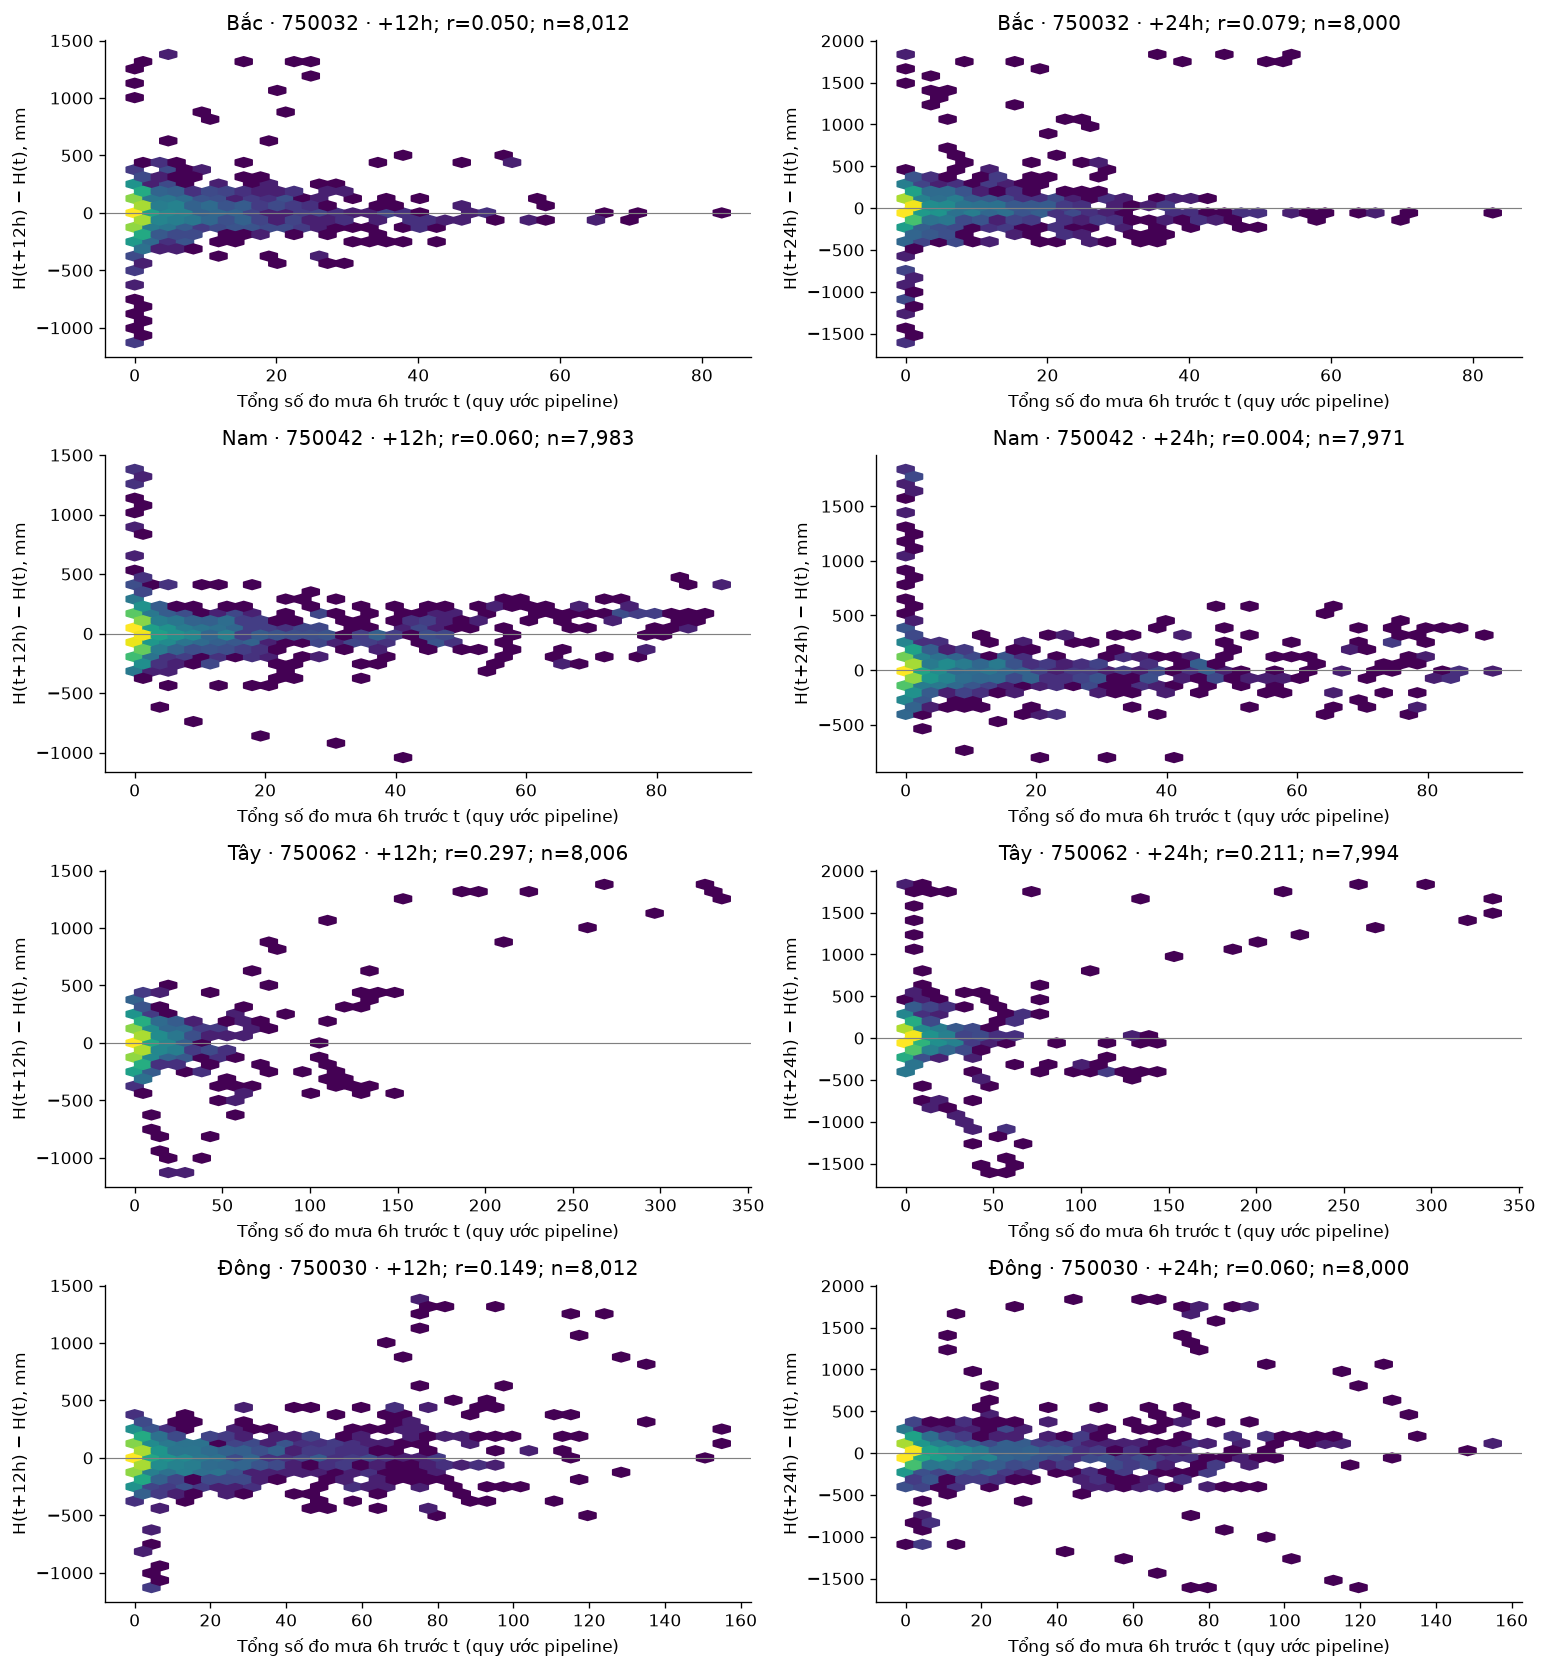

,split,station_id,name,direction,horizon,pearson,spearman,n,coverage,qualified
256,all,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,12,0.050,0.015,8012,1.000,True
1906,test,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,12,0.002,-0.003,699,1.000,True
806,train,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,12,0.090,0.000,6173,1.000,True
1356,val,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,12,0.004,0.128,1068,1.000,True
311,all,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,24,0.079,-0.058,8000,1.000,True
1961,test,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,24,-0.188,-0.072,687,1.000,True
861,train,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,24,0.177,-0.096,6161,1.000,True
1411,val,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,24,0.065,0.167,1056,1.000,True
262,all,750042,Trạm kiểm lâm Khe Mỏ Rang,Nam,12,0.060,0.015,7983,0.996,True
1912,test,750042,Trạm kiểm lâm Khe Mỏ Rang,Nam,12,0.048,-0.075,699,1.000,True


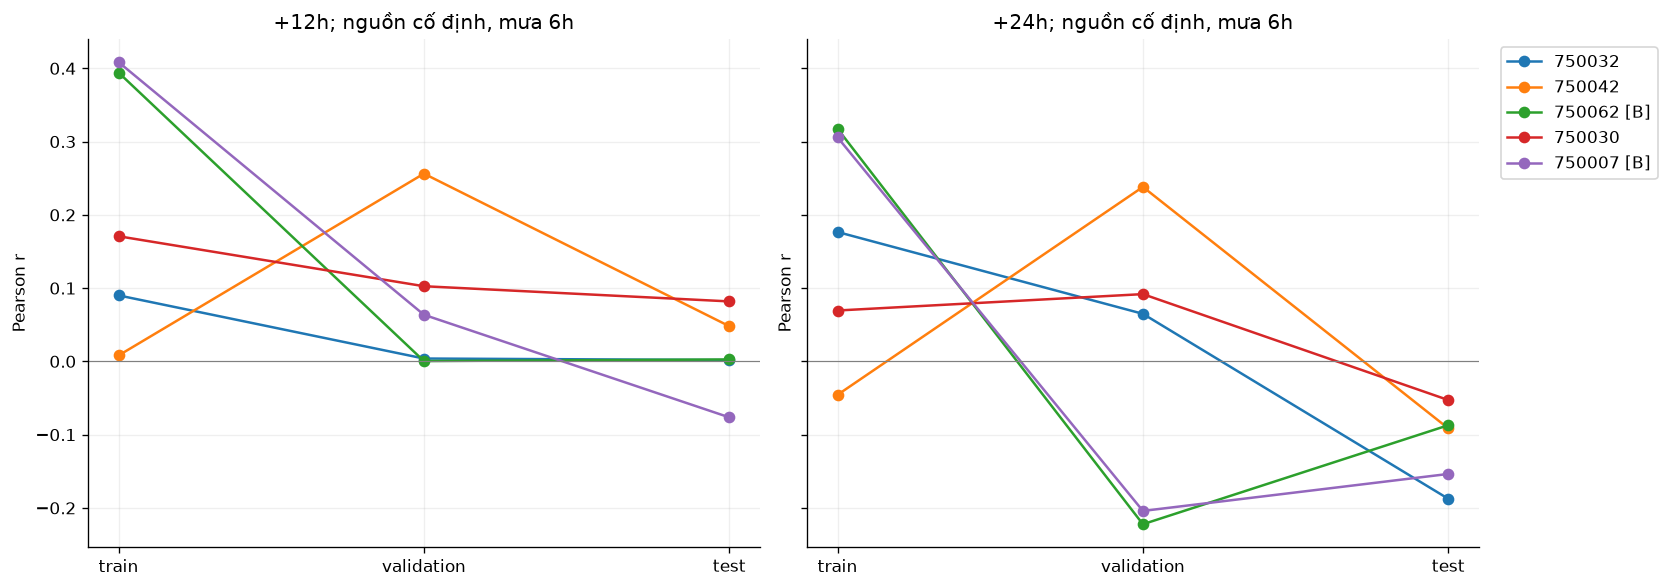

station_id,750032,750042,750062,750030,750007
station_id,,,,,
750032,1.000,0.378,0.241,0.493,0.258
750042,0.378,1.000,0.306,0.581,0.373
750062,0.241,0.306,1.000,0.488,0.941
750030,0.493,0.581,0.488,1.000,0.476
750007,0.258,0.373,0.941,0.476,1.000


station_id,750032,750042,750062,750030,750007
station_id,,,,,
750032,8024,7995,8018,8024,8024
750042,7995,7995,7989,7995,7995
750062,8018,7989,8018,8018,8018
750030,8024,7995,8018,8024,8024
750007,8024,7995,8018,8024,8024


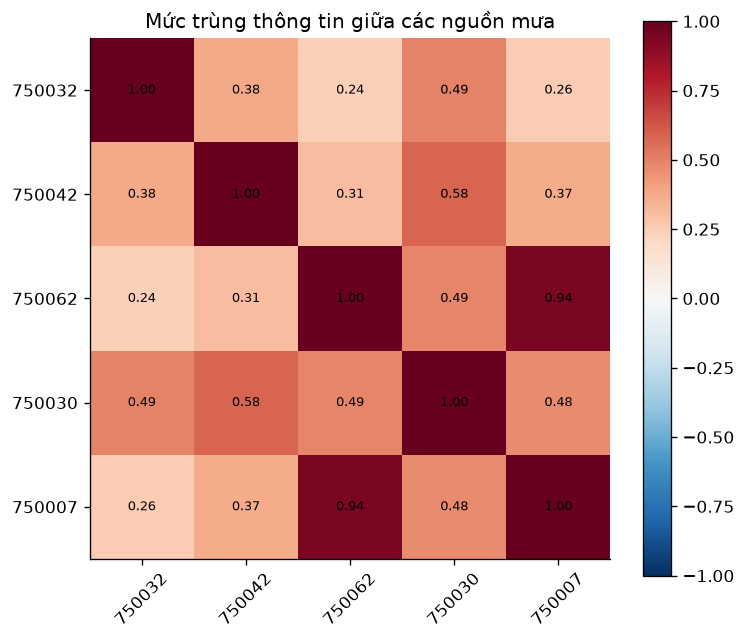

In [7]:
if len(selected_all):
    fig, axes = plt.subplots(len(selected_all), 2, figsize=(13, 3.5 * len(selected_all)), squeeze=False)
    for row_axes, (_, station) in zip(axes, selected_all.iterrows()):
        for ax, h in zip(row_axes, HORIZONS):
            paired = pd.concat([accumulated[PRIMARY_WINDOW][station.station_id].rename("rain"), delta[h].rename("delta")], axis=1).dropna()
            ax.hexbin(paired.rain, paired.delta, gridsize=35, mincnt=1, bins="log", cmap="viridis")
            ax.axhline(0, color="grey", linewidth=.7)
            ax.set_title(f"{station.direction} · {station.station_id} · +{h}h; r={paired.rain.corr(paired.delta):.3f}; n={len(paired):,}")
            ax.set_xlabel(f"Tổng số đo mưa {PRIMARY_WINDOW}h trước t (quy ước pipeline)")
            ax.set_ylabel(f"H(t+{h}h) − H(t), mm")
    fig.tight_layout()
    show()

selected_ids = list(dict.fromkeys([*selected_all.station_id, *sorted(MODEL_B)]))
stability = primary.loc[primary.station_id.isin(selected_ids), ["split", "station_id", "name", "direction", "horizon", "pearson", "spearman", "n", "coverage", "qualified"]]
display(stability.sort_values(["direction", "station_id", "horizon", "split"]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, h in zip(axes, HORIZONS):
    for sid in selected_ids:
        group = stability.loc[stability.station_id.eq(sid) & stability.horizon.eq(h)].set_index("split").reindex(["train", "val", "test"])
        ax.plot([0, 1, 2], group.pearson, marker="o", label=f"{sid} {'[B]' if sid in MODEL_B else ''}")
    ax.set_xticks([0, 1, 2], ["train", "validation", "test"])
    ax.axhline(0, color="grey", linewidth=.7)
    ax.set(title=f"+{h}h; nguồn cố định, mưa {PRIMARY_WINDOW}h", ylabel="Pearson r")
    ax.grid(alpha=.2)
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
show()

# Mức trùng thông tin mưa giữa nguồn được chọn và hai nguồn B.
redundancy = accumulated[PRIMARY_WINDOW][selected_ids].corr(min_periods=MIN_PAIRS)
print("Pearson giữa các nguồn mưa — pairwise; xem cả số cặp:")
display(redundancy.round(3))
present = accumulated[PRIMARY_WINDOW][selected_ids].notna().astype(int)
display(present.T.dot(present))
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(redundancy, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(selected_ids)), selected_ids, rotation=45)
ax.set_yticks(range(len(selected_ids)), selected_ids)
for i in range(len(selected_ids)):
    for j in range(len(selected_ids)):
        ax.text(j, i, f"{redundancy.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Mức trùng thông tin giữa các nguồn mưa")
fig.colorbar(image, ax=ax)
show()

## 7. Kết luận tự cập nhật
Các trạm dưới đây là ứng viên để thử nghiệm sau này, chưa phải cấu hình model mới. Giữ nguyên Model B. Ưu tiên kiểm tra cả r12 và r24 thay vì chỉ một điểm số gộp; correlation âm hoặc yếu ở một horizon cần được nhìn riêng.


In [8]:
lines = ["### Kết quả trên toàn giai đoạn"]
for direction in DIRECTIONS:
    group = selected_all.loc[selected_all.direction.eq(direction)]
    if group.empty:
        lines.append(f"- **{direction}:** chưa có trạm đủ điều kiện và score dương.")
    else:
        row = group.iloc[0]
        lines.append(f"- **{direction}: {row.station_id} — {row['name']}**, r12={row.r12:.3f}, r24={row.r24:.3f}, score={row.score:.3f}; {row.n:,} anchor chung trong hướng.")
lines += ["", "### Lựa chọn chỉ trên train"]
for _, row in winners.loc[winners.split.eq("train")].iterrows():
    lines.append(f"- **{row.direction}: {row.station_id} — {row['name']}**, r12={row.r12:.3f}, r24={row.r24:.3f}.")
lines += ["", "Không suy ra rằng thêm các trạm này sẽ giảm lỗi >200 mm. Cần thí nghiệm đối chứng cùng anchor và đánh giá trên giai đoạn mới để kiểm chứng lợi ích ở +12/+24h."]
display(Markdown("\n".join(lines)))

# Kiểm tra tính nhất quán ngay trong notebook.
assert index.is_monotonic_increasing and index.is_unique
assert (index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert not winners.duplicated(["split", "direction"]).any()
assert winners.n.ge(MIN_PAIRS).all()
assert winners.coverage.ge(MIN_COMMON_COVERAGE).all()
assert set(catalog.loc[catalog.model_B, "direction"]) == {"Tây"}
print("Kiểm tra lưới giờ, quy tắc chọn trạm và hướng của Model B: PASS")

Kiểm tra lưới giờ, quy tắc chọn trạm và hướng của Model B: PASS


### Kết quả trên toàn giai đoạn
- **Bắc: 750032 — Trạm bơm Quảng Thành (Quảng Điền)**, r12=0.051, r24=0.079, score=0.065; 7,835 anchor chung trong hướng.
- **Đông: 750030 — Vườn Quốc gia Bạch Mã (Phú Lộc)**, r12=0.156, r24=0.068, score=0.112; 6,832 anchor chung trong hướng.
- **Nam: 750042 — Trạm kiểm lâm Khe Mỏ Rang**, r12=0.096, r24=0.041, score=0.068; 6,636 anchor chung trong hướng.
- **Tây: 750062 — Hồng Thái (A Lưới)**, r12=0.367, r24=0.333, score=0.350; 7,286 anchor chung trong hướng.

### Lựa chọn chỉ trên train
- **Bắc: 750032 — Trạm bơm Quảng Thành (Quảng Điền)**, r12=0.091, r24=0.177.
- **Nam: 750061 — Thủy điện Bình Điền (Hương Trà)**, r12=0.287, r24=0.207.
- **Tây: 750062 — Hồng Thái (A Lưới)**, r12=0.491, r24=0.487.
- **Đông: 750027 — Thủy Thanh (Hương Thủy)**, r12=0.090, r24=0.235.

Không suy ra rằng thêm các trạm này sẽ giảm lỗi >200 mm. Cần thí nghiệm đối chứng cùng anchor và đánh giá trên giai đoạn mới để kiểm chứng lợi ích ở +12/+24h.